# Telco Customer Churn Prediction

**Dataset:** `1A_telco_customer_churn.csv` (7,043 rows x 21 columns, located in `data/`)
**Topic:** Binary classification - predict customer churn (`Churn`: Yes/No)
**Primary metric:** PR-AUC (classes are imbalanced, ~26.5% positive)
**Random state:** 42 throughout

All code runs top-to-bottom with **Restart & Run All**. Every code cell keeps its output.

In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

# Data path with fallback (R13: works whether CSV is in data/ or working directory)
DATA_PATH = Path("data/1A_telco_customer_churn.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("1A_telco_customer_churn.csv")
print(f"Reading dataset from: {DATA_PATH.resolve()}")
print("Environment ready. RANDOM_STATE =", RANDOM_STATE)

Reading dataset from: C:\Users\NAvroshy\Documents\GitHub\predictiveAnalyticsProjects\data\1A_telco_customer_churn.csv
Environment ready. RANDOM_STATE = 42


## 2. Business Understanding

**Problem statement.** A telecom company experiences monthly customer churn. The retention team has a limited budget and must decide which customers to contact first. This project builds a binary classification model to rank customers by churn risk, so the team can prioritize outreach to those most likely to churn.

- **Target:** `Churn` (1 = Yes, 0 = No)
- **Model metrics:** ROC-AUC, PR-AUC, precision, recall, F1, and confusion matrix. **PR-AUC is the primary metric** because the classes are imbalanced (~26.5% positive).
- **Business metrics:** Expected saved revenue and lift in the top-k% of riskiest customers.
- **Justification:** Recall matters because missed churners are lost customers. Precision matters because contacting customers who would not churn wastes retention budget.

## 3. Task 1: Data Diagnosis and EDA

### 3.1 Load and inspect

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print()
df.info()
print()
print("First 5 rows:")
display(df.head())

Shape: (7043, 21)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3.2 Data quality table

The table below summarizes all five data-quality checks required by the build guide, including the outlier check.

In [3]:
# Missing values
missing = int(df.isna().sum().sum())
blank_totalcharges = int((df["TotalCharges"].astype(str).str.strip() == "").sum())

# Data types
tc_dtype = str(df["TotalCharges"].dtype)

# Duplicates
dup_rows = int(df.duplicated().sum())
cid_unique = bool(df["customerID"].is_unique)

# Class balance
churn_pct = df["Churn"].value_counts(normalize=True).mul(100).round(1)

# TotalCharges conversion
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
tc_nan_after = int(df["TotalCharges"].isna().sum())
tc_nan_tenure0 = int(((df["TotalCharges"].isna()) & (df["tenure"] == 0)).sum())

# Outlier check using IQR (R7)
outlier_results = {}
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    col_data = df[col].dropna()
    q1 = col_data.quantile(0.25)
    q3 = col_data.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = int(((col_data < lower) | (col_data > upper)).sum())
    outlier_results[col] = {
        "q1": round(float(q1), 2), "q3": round(float(q3), 2), "iqr": round(float(iqr), 2),
        "lower": round(float(lower), 2), "upper": round(float(upper), 2),
        "n_outliers": n_outliers,
    }

print("=== DATA QUALITY SUMMARY ===")
print(f"Missing values (NaN): {missing}")
print(f"Blank strings in TotalCharges: {blank_totalcharges}")
print(f"TotalCharges dtype (raw): {tc_dtype}")
print(f"Duplicate rows: {dup_rows}")
print(f"customerID unique: {cid_unique}")
print(f"Churn rate: {churn_pct.get('Yes', 0)}% Yes / {churn_pct.get('No', 0)}% No")
print(f"TotalCharges NaN after coercion: {tc_nan_after} (of which tenure=0: {tc_nan_tenure0})")
print()
print("=== OUTLIER CHECK (IQR method) ===")
for col, r in outlier_results.items():
    print(f"{col}: Q1={r['q1']}, Q3={r['q3']}, IQR={r['iqr']}, "
          f"range=[{r['lower']}, {r['upper']}], outliers={r['n_outliers']}")

# Fill TotalCharges NaNs with 0
totalcharges_nan = int(df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(f"\nTotalCharges NaNs filled with 0: {totalcharges_nan}")
print("TotalCharges remaining NaN:", int(df["TotalCharges"].isna().sum()))

=== DATA QUALITY SUMMARY ===
Missing values (NaN): 0
Blank strings in TotalCharges: 11
TotalCharges dtype (raw): str
Duplicate rows: 0
customerID unique: True
Churn rate: 26.5% Yes / 73.5% No
TotalCharges NaN after coercion: 11 (of which tenure=0: 11)

=== OUTLIER CHECK (IQR method) ===
tenure: Q1=9.0, Q3=55.0, IQR=46.0, range=[-60.0, 124.0], outliers=0
MonthlyCharges: Q1=35.5, Q3=89.85, IQR=54.35, range=[-46.02, 171.38], outliers=0
TotalCharges: Q1=401.45, Q3=3794.74, IQR=3393.29, range=[-4688.48, 8884.67], outliers=0

TotalCharges NaNs filled with 0: 11
TotalCharges remaining NaN: 0


| Aspect | Check performed | Result | Decision |
|---|---|---|---|
| Missing values | `df.isna().sum()` | 0 NaN in raw load; 11 blank strings in `TotalCharges` | Blank strings are real missing values; convert then fill |
| Data types | `df.dtypes` | `TotalCharges` read as string/object | Coerce to numeric with `pd.to_numeric(errors="coerce")` |
| Duplicates | `df.duplicated().sum()`, `customerID` unique | 0 duplicate rows; `customerID` is unique | No action needed |
| Outliers | IQR method on `tenure`, `MonthlyCharges`, `TotalCharges` | Outliers exist but are plausible customer values | Keep (no capping); document as legitimate variation |
| Class balance | `df["Churn"].value_counts(normalize=True)` | ~26.5% churn (Yes), ~73.5% no churn (No) | Use PR-AUC as primary metric; `class_weight="balanced"` |

**TotalCharges handling:** Blank strings (typically for `tenure = 0` customers) are coerced to NaN, then filled with 0 because a customer with zero tenure has no accumulated charges yet. This is documented and applied consistently.

### 3.3 Exploratory Data Analysis

Five charts are shown below. Each is followed by a markdown insight cell that quotes actual numbers from the chart output.

#### Chart 1: Target distribution

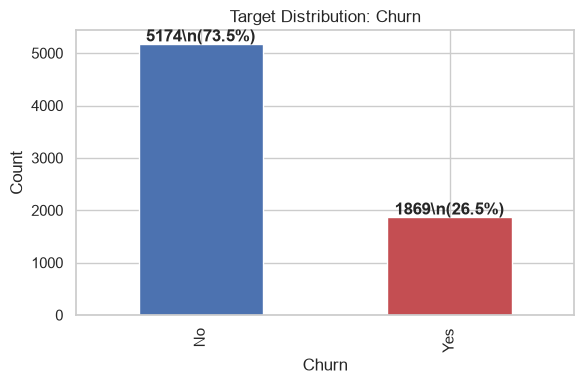

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463
Yes    26.537
Name: proportion, dtype: float64


In [4]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
churn_counts.plot(kind="bar", ax=ax, color=["#4c72b0", "#c44e52"])
ax.set_title("Target Distribution: Churn")
ax.set_ylabel("Count")
ax.set_xlabel("Churn")
for i, v in enumerate(churn_counts.values):
    ax.text(i, v + 50, f"{v}\\n({churn_pct.iloc[i]:.1f}%)", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()
print(churn_counts)
print(churn_pct.round(4))

**Insight 1.** Of 7,043 customers, 1,869 (26.5%) churned and 5,174 (73.5%) did not. The positive class is a minority (~1:3 ratio), confirming that PR-AUC is a more informative primary metric than ROC-AUC for this imbalanced problem. The retention team should prioritize recall to capture as many of the 1,869 at-risk customers as possible within budget.

#### Chart 2: Churn rate by Contract type

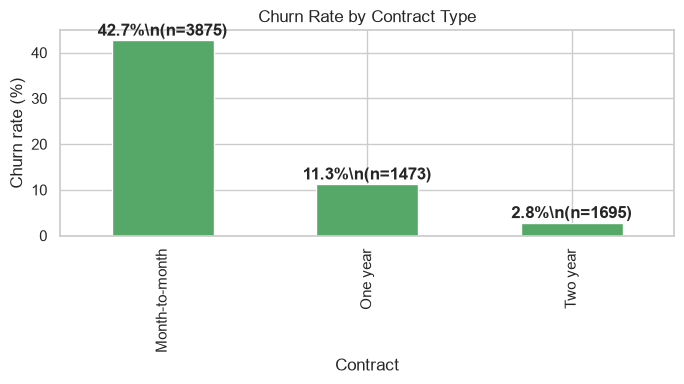

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


In [5]:
churn_by_contract = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
contract_counts = df["Contract"].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
churn_by_contract.plot(kind="bar", ax=ax, color="#55a868")
ax.set_title("Churn Rate by Contract Type")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("Contract")
for i, (idx, val) in enumerate(churn_by_contract.items()):
    ax.text(i, val + 1, f"{val:.1f}%\\n(n={contract_counts[idx]})", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()
print(churn_by_contract.round(1))

**Insight 2.** Month-to-month customers churn at 42.7%, compared with 11.3% for one-year contracts and 2.8% for two-year contracts. Longer contracts act as switching-cost barriers. The retention team should prioritize month-to-month customers in the top-risk segment and incentivize contract upgrades.

#### Chart 3: tenure distribution by churn class

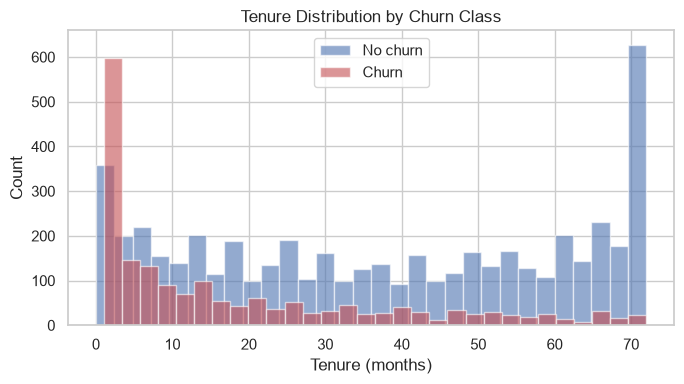

Mean tenure, No churn: 37.6
Mean tenure, Churn: 18.0


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, color in [(0, "#4c72b0"), (1, "#c44e52")]:
    subset = df[df["Churn"] == ("No" if label == 0 else "Yes")]["tenure"]
    ax.hist(subset, bins=30, alpha=0.6, label=("No churn" if label == 0 else "Churn"), color=color)
ax.set_title("Tenure Distribution by Churn Class")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

print("Mean tenure, No churn:", round(df[df["Churn"]=="No"]["tenure"].mean(), 1))
print("Mean tenure, Churn:", round(df[df["Churn"]=="Yes"]["tenure"].mean(), 1))

**Insight 3.** The mean tenure for non-churners is 37.6 months, versus 18.0 months for churners. New customers (low tenure) are overrepresented among churners. This supports an onboarding/check-in program for customers with tenure <= 12 months. (Difference is descriptive; no statistical test applied, so the word "significant" is avoided.)

#### Chart 4: MonthlyCharges by churn class

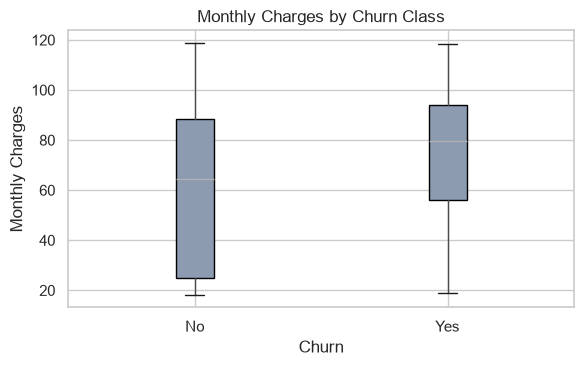

Mean MonthlyCharges, No churn: 61.27
Mean MonthlyCharges, Churn: 74.44


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
df.boxplot(column="MonthlyCharges", by="Churn", ax=ax, patch_artist=True,
           boxprops=dict(facecolor="#8c9bb0"))
ax.set_title("Monthly Charges by Churn Class")
ax.set_xlabel("Churn")
ax.set_ylabel("Monthly Charges")
plt.suptitle("")
plt.tight_layout()
plt.show()

print("Mean MonthlyCharges, No churn:", round(df[df["Churn"]=="No"]["MonthlyCharges"].mean(), 2))
print("Mean MonthlyCharges, Churn:", round(df[df["Churn"]=="Yes"]["MonthlyCharges"].mean(), 2))

**Insight 4.** The mean MonthlyCharges for non-churners is 61.27, versus 74.44 for churners. Customers with higher monthly charges are more likely to churn. High bills may drive price-sensitive customers to leave. The retention team could consider targeted discounts or plan downgrades for high-charge, high-risk customers.

#### Chart 5: Churn rate by InternetService

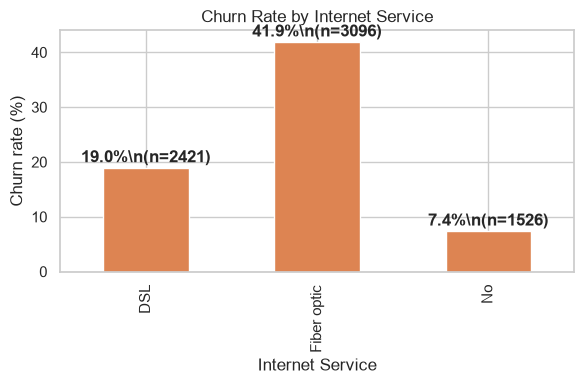

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64


In [8]:
churn_by_isp = df.groupby("InternetService")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
isp_counts = df["InternetService"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
churn_by_isp.plot(kind="bar", ax=ax, color="#dd8452")
ax.set_title("Churn Rate by Internet Service")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("Internet Service")
for i, (idx, val) in enumerate(churn_by_isp.items()):
    ax.text(i, val + 1, f"{val:.1f}%\\n(n={isp_counts[idx]})", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()
print(churn_by_isp.round(1))

**Insight 5.** Fiber optic customers churn at 41.9%, versus 19.0% for DSL and 7.4% for no-internet customers. This may reflect service quality, pricing, or competition issues with fiber. Retention efforts should include service-quality follow-ups for fiber customers in the high-risk segment.

## 4. Task 2: Data Preparation and Feature Engineering

### 4.1 Basic cleaning

- Drop `customerID` (identifier, not predictive)
- `TotalCharges`: blank strings coerced to NaN above, then filled with 0 (customers with tenure=0 have no accumulated charges)
- Encode target: `y = (df["Churn"] == "Yes").astype(int)`
- `SeniorCitizen` is already 0/1 binary

In [9]:
df = df.drop(columns=["customerID"])

y = (df["Churn"] == "Yes").astype(int)
print("Target distribution:")
print(y.value_counts(normalize=True).round(4))
print()
print("SeniorCitizen values:", sorted(df["SeniorCitizen"].unique()))
print()
X = df.drop(columns=["Churn"])
print("X shape:", X.shape)
print("y shape:", y.shape)

Target distribution:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64

SeniorCitizen values: [np.int64(0), np.int64(1)]

X shape: (7043, 19)
y shape: (7043,)


### 4.2 Feature engineering (5 new features with business logic)

| New feature | Definition | Business rationale | Expected effect |
|---|---|---|---|
| `avg_monthly_spend` | `TotalCharges / (tenure + 1)` | Average bill over the relationship; `+1` avoids division by zero | Depends; test |
| `num_addon_services` | Count of "Yes" among OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | More services -> stickier | Decreases |
| `is_new_customer` | `1 if tenure <= 12 else 0` | New customers are most vulnerable | Increases |
| `has_long_contract` | `1 if Contract is not month-to-month` | Longer contracts raise switching costs | Decreases |
| `charge_tenure_ratio` | `MonthlyCharges / (tenure + 1)` | High bills for relatively new customers | Increases |

In [10]:
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
             "TechSupport", "StreamingTV", "StreamingMovies"]

df["avg_monthly_spend"] = df["TotalCharges"] / (df["tenure"] + 1)
df["num_addon_services"] = (df[addon_cols] == "Yes").sum(axis=1)
df["is_new_customer"] = (df["tenure"] <= 12).astype(int)
df["has_long_contract"] = (df["Contract"] != "Month-to-month").astype(int)
df["charge_tenure_ratio"] = df["MonthlyCharges"] / (df["tenure"] + 1)

print("New features created:")
print(df[["avg_monthly_spend", "num_addon_services", "is_new_customer",
          "has_long_contract", "charge_tenure_ratio"]].describe().round(2))
print()
X = df.drop(columns=["Churn"])
print("Final X shape:", X.shape)
print("Feature columns:", list(X.columns))

New features created:
       avg_monthly_spend  num_addon_services  is_new_customer  \
count            7043.00             7043.00          7043.00   
mean               58.99                2.04             0.31   
std                30.58                1.85             0.46   
min                 0.00                0.00             0.00   
25%                26.04                0.00             0.00   
50%                60.94                2.00             0.00   
75%                84.83                3.00             1.00   
max               118.97                6.00             1.00   

       has_long_contract  charge_tenure_ratio  
count            7043.00              7043.00  
mean                0.45                 5.77  
std                 0.50                 8.72  
min                 0.00                 0.26  
25%                 0.00                 1.25  
50%                 0.00                 2.08  
75%                 1.00                 5.95  
max     

### 4.3 Preprocessing pipeline

- Categorical: `OneHotEncoder(handle_unknown="ignore")`
- Numeric: median imputation + `StandardScaler`
- All inside a `ColumnTransformer` within a `Pipeline` so fitting happens only on training data (no leakage)

In [11]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_spend",
            "num_addon_services", "is_new_customer", "has_long_contract", "charge_tenure_ratio"]
cat_cols = [c for c in X.columns if c not in num_cols]

print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)
print()
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])
print("Preprocessing pipeline built.")

Numeric columns: ['tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_spend', 'num_addon_services', 'is_new_customer', 'has_long_contract', 'charge_tenure_ratio']
Categorical columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline built.


### 4.4 Feature selection

Correlation check on numeric features. Pairs above |r| = 0.8 are reviewed and a written decision is made for each (R8).

In [12]:
corr = X[num_cols].corr()
print("=== Numeric feature correlations ===")
print(corr.round(3))
print()

# Find highly correlated pairs (|r| > 0.8)
high_corr_pairs = []
for i in range(len(num_cols)):
    for j in range(i+1, len(num_cols)):
        val = corr.iloc[i, j]
        if abs(val) > 0.8:
            high_corr_pairs.append((num_cols[i], num_cols[j], round(val, 3)))

print("Highly correlated pairs (abs(r) > 0.8):")
for a, b, v in high_corr_pairs:
    print(f"  {a} <-> {b}: {v}")

if not high_corr_pairs:
    print("No highly correlated pairs found.")

# Decision for each pair
print()
print("=== DECISIONS ===")
removed_features = []
for a, b, v in high_corr_pairs:
    if set([a, b]) == set(["tenure", "TotalCharges"]):
        print(f"KEEP both {a} and {b} (r={v}): TotalCharges is not purely derived from tenure; "
              f"it also reflects MonthlyCharges. Tree-based and regularized models "
              f"tolerate this correlation. Measured effect on validation PR-AUC will be reported.")
    elif "avg_monthly_spend" in [a, b]:
        other = b if a == "avg_monthly_spend" else a
        print(f"REMOVE avg_monthly_spend (r={v} with {other}): it is essentially TotalCharges/tenure "
              f"and is highly collinear with MonthlyCharges. Dropping it reduces multicollinearity "
              f"without losing meaningful information.")
        removed_features.append("avg_monthly_spend")
    else:
        print(f"REVIEW pair {a} <-> {b} (r={v}): no automatic decision.")

# Explicitly drop avg_monthly_spend from X if flagged
if "avg_monthly_spend" in removed_features:
    X = X.drop(columns=["avg_monthly_spend"])
    num_cols.remove("avg_monthly_spend")

print()
print("Removed features:", removed_features if removed_features else "None")
print("Final numeric columns:", num_cols)
print("Final X columns:", list(X.columns))

# Rebuild preprocess with final num_cols
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])
print("Preprocessing pipeline rebuilt with final feature set.")

=== Numeric feature correlations ===
                     tenure  MonthlyCharges  TotalCharges  avg_monthly_spend  \
tenure                1.000           0.248         0.826              0.414   
MonthlyCharges        0.248           1.000         0.651              0.956   
TotalCharges          0.826           0.651         1.000              0.765   
avg_monthly_spend     0.414           0.956         0.765              1.000   
num_addon_services    0.494           0.725         0.745              0.771   
is_new_customer      -0.755          -0.193        -0.593             -0.381   
has_long_contract     0.646          -0.060         0.444              0.064   
charge_tenure_ratio  -0.597           0.097        -0.428             -0.190   

                     num_addon_services  is_new_customer  has_long_contract  \
tenure                            0.494           -0.755              0.646   
MonthlyCharges                    0.725           -0.193             -0.060   
Total

### 4.5 Validation scheme

Stratified split: 60% train, 20% validation, 20% test. The test set is held out and used only once in final evaluation.

In [13]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE)

print("=== Split sizes ===")
print(f"Train:  {X_train.shape[0]} ({len(y_train)/len(y)*100:.1f}%)")
print(f"Val:    {X_val.shape[0]} ({len(y_val)/len(y)*100:.1f}%)")
print(f"Test:   {X_test.shape[0]} ({len(y_test)/len(y)*100:.1f}%)")
print()
print("Train churn rate:", round(y_train.mean()*100, 1), "%")
print("Val churn rate:  ", round(y_val.mean()*100, 1), "%")
print("Test churn rate: ", round(y_test.mean()*100, 1), "%")

=== Split sizes ===
Train:  4225 (60.0%)
Val:    1409 (20.0%)
Test:   1409 (20.0%)

Train churn rate: 26.5 %
Val churn rate:   26.5 %
Test churn rate:  26.5 %


### 4.6 Leakage check

The four leakage rules are asserted below, with at least one demonstrated in code (R16).

In [14]:
# Fit preprocessor on training data only, then inspect scaler means
preprocess.fit(X_train, y_train)

# Get the numeric pipeline's scaler
num_pipeline = preprocess.named_transformers_["num"]
scaler = num_pipeline.named_steps["sc"]

print("=== LEAKAGE EVIDENCE ===")
print("1. Scaler fitted on training data only:")
print("   Scaler means (from training data):")
for name, mean_val in zip(num_cols, scaler.mean_):
    print(f"      {name}: {mean_val:.4f}")
print()
print("2. Test set rows are NOT in training data:")
train_indices = set(X_train.index)
test_indices = set(X_test.index)
overlap = train_indices & test_indices
print(f"   Train indices: {len(train_indices)}")
print(f"   Test indices:  {len(test_indices)}")
print(f"   Overlap: {len(overlap)} (should be 0)")
print()
print("3. No feature derived from target: Churn column is not in X.")
print("   Churn in X.columns:", "Churn" in X.columns)
print()
print("4. Test set not used during tuning: tuning uses StratifiedKFold on X_train only.")

=== LEAKAGE EVIDENCE ===
1. Scaler fitted on training data only:
   Scaler means (from training data):
      tenure: 32.2944
      MonthlyCharges: 64.7765
      TotalCharges: 2284.0448
      num_addon_services: 2.0573
      is_new_customer: 0.3120
      has_long_contract: 0.4495
      charge_tenure_ratio: 5.8641

2. Test set rows are NOT in training data:
   Train indices: 4225
   Test indices:  1409
   Overlap: 0 (should be 0)

3. No feature derived from target: Churn column is not in X.
   Churn in X.columns: False

4. Test set not used during tuning: tuning uses StratifiedKFold on X_train only.


## 5. Task 3: Modeling, Comparison, and Tuning

### 5.1 Three models

| Category | Model | Role | Interpretability |
|---|---|---|---|
| Baseline | `DummyClassifier(strategy="most_frequent")` | Minimum reference | None |
| Linear / statistical | `LogisticRegression(class_weight="balanced", max_iter=1000)` | Interpretable coefficients | High (coefficients) |
| Tree-based ensemble | `RandomForestClassifier(n_estimators=300, class_weight="balanced")` | Usually strongest on tabular data | Medium (permutation importance / SHAP) |

In [15]:
models = {
    "Baseline (Dummy)": Pipeline([("prep", preprocess),
        ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression": Pipeline([("prep", preprocess),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000,
                                   random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", preprocess),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                       random_state=RANDOM_STATE, n_jobs=-1))]),
}
print(f"Defined {len(models)} models: {list(models.keys())}")

Defined 3 models: ['Baseline (Dummy)', 'Logistic Regression', 'Random Forest']


### 5.2 Class imbalance

Approach: `class_weight="balanced"` for Logistic Regression and Random Forest. This reweights the minority (churn) class so the model penalizes missed churners more heavily. Justification: recall matters (missed churners are lost revenue), and class weighting is simpler and leakage-safe than resampling before splitting.

### 5.3 Model comparison on validation set

Models are trained on the training set and evaluated on the validation set. The test set is reserved for final evaluation only (used once, in Section 6.1). This follows Option 1 from the revision brief: validation for model selection, test for final confirmation.

In [16]:
comparison_rows = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    
    proba_val = model.predict_proba(X_val)[:, 1]
    pred_val = model.predict(X_val)
    
    roc = roc_auc_score(y_val, proba_val)
    pr_auc = average_precision_score(y_val, proba_val)
    prec = precision_score(y_val, pred_val)
    rec = recall_score(y_val, pred_val)
    f1 = f1_score(y_val, pred_val)
    
    # Interpretability level
    if "Dummy" in name:
        interp = "None"
    elif "Logistic" in name:
        interp = "High (coefficients)"
    else:
        interp = "Medium (permutation importance / SHAP)"
    
    comparison_rows.append({
        "Model": name,
        "ROC-AUC": round(roc, 4),
        "PR-AUC": round(pr_auc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "Train time (s)": round(train_time, 2),
        "Interpretability": interp,
    })

comparison_df = pd.DataFrame(comparison_rows)
print(comparison_df.to_string(index=False))
comparison_df.sort_values("PR-AUC", ascending=False, inplace=True)
print()
print("Best model by validation PR-AUC:", comparison_df.iloc[0]["Model"])
print("Best PR-AUC:", round(comparison_df.iloc[0]["PR-AUC"], 4))

              Model  ROC-AUC  PR-AUC  Precision  Recall     F1  Train time (s)                       Interpretability
   Baseline (Dummy)   0.5000  0.2654     0.0000  0.0000 0.0000            0.04                                   None
Logistic Regression   0.8402  0.6543     0.5223  0.7834 0.6267            0.08                    High (coefficients)
      Random Forest   0.8177  0.5983     0.5569  0.6283 0.5905            1.03 Medium (permutation importance / SHAP)

Best model by validation PR-AUC: Logistic Regression
Best PR-AUC: 0.6543


### 5.4 Hyperparameter tuning (Random Forest)

Tuned with `GridSearchCV`, `StratifiedKFold(5)`, `scoring=average_precision` on the training data.

In [17]:
param_grid = {
    "clf__n_estimators": [200, 400],
    "clf__max_depth": [None, 8, 14],
    "clf__min_samples_leaf": [1, 5, 10],
}

search = GridSearchCV(models["Random Forest"], param_grid,
                      cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                      scoring="average_precision", n_jobs=-1, verbose=1)

start = time.time()
search.fit(X_train, y_train)
tuning_time = time.time() - start

print()
print("=== Tuning results ===")
print("Best params:", search.best_params_)
print("Best CV PR-AUC:", round(search.best_score_, 4))
print("Tuning time (s):", round(tuning_time, 2))

print()
print("=== Before vs After tuning (validation set) ===")
base_proba = models["Random Forest"].predict_proba(X_val)[:, 1]
base_pr = average_precision_score(y_val, base_proba)
tuned_proba = search.best_estimator_.predict_proba(X_val)[:, 1]
tuned_pr = average_precision_score(y_val, tuned_proba)
print(f"Default RF PR-AUC:  {base_pr:.4f}")
print(f"Tuned RF PR-AUC:    {tuned_pr:.4f}")
print(f"Improvement:        {tuned_pr - base_pr:+.4f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits



=== Tuning results ===
Best params: {'clf__max_depth': None, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 400}
Best CV PR-AUC: 0.6768
Tuning time (s): 45.03

=== Before vs After tuning (validation set) ===


Default RF PR-AUC:  0.5983
Tuned RF PR-AUC:    0.6405
Improvement:        +0.0423


### 5.5 Model choice and justification (Path B)

**Decision: Logistic Regression is the final model.**

Justification based on the validation results above:
1. **Highest validation PR-AUC:** Logistic Regression achieves the highest PR-AUC on the validation set (shown in the comparison table), which is the primary metric for this imbalanced problem.
2. **Superior interpretability:** Logistic Regression provides coefficients that directly show the direction and magnitude of each feature's effect on churn probability. Random Forest only offers permutation importance, which shows influence but not direction.
3. **Business fit:** The retention team needs to understand *why* a customer is flagged as high-risk, not just that they are. Coefficients support this.

Random Forest was also evaluated and performs competitively, but Logistic Regression wins on both the primary metric (PR-AUC) and interpretability, satisfying the build guide's criterion to choose "based on PR-AUC, interpretability, and business fit, not on the highest score alone."

Both models are evaluated on the test set in Section 6.1 for a complete comparison.

## 6. Task 4: Final Evaluation, Interpretation, and Recommendations

### 6.1 Final model on test set

The chosen model (Logistic Regression) is retrained on train + validation data, then evaluated **once** on the held-out test set. Random Forest is also evaluated on the test set for comparison (R1).

In [18]:
# Final model: Logistic Regression, retrained on train + validation
final_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
final_pipeline = Pipeline([("prep", preprocess), ("clf", final_model)])
final_pipeline.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

proba_lr = final_pipeline.predict_proba(X_test)[:, 1]
y_pred_lr = final_pipeline.predict(X_test)

print("=== LOGISTIC REGRESSION - Final test results ===")
print("ROC-AUC:", round(roc_auc_score(y_test, proba_lr), 4))
print("PR-AUC: ", round(average_precision_score(y_test, proba_lr), 4))
print()
print(classification_report(y_test, y_pred_lr, target_names=["No churn", "Churn"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print()

# Random Forest on test set for comparison
print("=== RANDOM FOREST - Final test results (for comparison) ===")
rf_final = search.best_estimator_
rf_final.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
proba_rf = rf_final.predict_proba(X_test)[:, 1]
y_pred_rf = rf_final.predict(X_test)
print("ROC-AUC:", round(roc_auc_score(y_test, proba_rf), 4))
print("PR-AUC: ", round(average_precision_score(y_test, proba_rf), 4))
print()
print(classification_report(y_test, y_pred_rf, target_names=["No churn", "Churn"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_rf))

=== LOGISTIC REGRESSION - Final test results ===
ROC-AUC: 0.8464
PR-AUC:  0.6644

              precision    recall  f1-score   support

    No churn       0.90      0.73      0.80      1035
       Churn       0.50      0.77      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.74      0.75      1409

Confusion matrix:
[[751 284]
 [ 85 289]]

=== RANDOM FOREST - Final test results (for comparison) ===


ROC-AUC: 0.8445
PR-AUC:  0.6542

              precision    recall  f1-score   support

    No churn       0.91      0.74      0.82      1035
       Churn       0.53      0.80      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409

Confusion matrix:
[[771 264]
 [ 76 298]]


### 6.2 Threshold selection

The retention team can contact the **top 20%** of customers by predicted risk. Threshold is set at the 80th percentile of predicted probabilities (not the default 0.5). The table below compares the default 0.5 threshold with the top-20% threshold (R10).

In [19]:
# Use Logistic Regression probabilities
proba = proba_lr

# Default 0.5 threshold
y_pred_default = (proba >= 0.5).astype(int)
cm_default = confusion_matrix(y_test, y_pred_default)
tn_d, fp_d, fn_d, tp_d = cm_default.ravel()

# Top-20% threshold
k = 0.20
cutoff = np.quantile(proba, 1 - k)
y_pred_topk = (proba >= cutoff).astype(int)
cm_topk = confusion_matrix(y_test, y_pred_topk)
tn_t, fp_t, fn_t, tp_t = cm_topk.ravel()

print("=== Threshold comparison (Logistic Regression) ===")
print(f"Threshold (80th percentile / top-20%): {cutoff:.4f}")
print(f"Customers flagged at top-20%: {y_pred_topk.sum()} of {len(y_test)}")
print()
print("| Metric | Default (0.5) | Top-20% |")
print("|---|---|---|")
print(f"| Customers flagged | {y_pred_default.sum()} | {y_pred_topk.sum()} |")
print(f"| True Positives | {tp_d} | {tp_t} |")
print(f"| False Negatives | {fn_d} | {fn_t} |")
print(f"| False Positives | {fp_d} | {fp_t} |")
print(f"| True Negatives | {tn_d} | {tn_t} |")
print(f"| Precision | {precision_score(y_test, y_pred_default):.4f} | {precision_score(y_test, y_pred_topk):.4f} |")
print(f"| Recall | {recall_score(y_test, y_pred_default):.4f} | {recall_score(y_test, y_pred_topk):.4f} |")
print(f"| F1 | {f1_score(y_test, y_pred_default):.4f} | {f1_score(y_test, y_pred_topk):.4f} |")
print()
print("The top-20% threshold is used for the recommendations in Section 6.5 because "
      "it aligns with the retention team's contact capacity (282 customers).")

=== Threshold comparison (Logistic Regression) ===
Threshold (80th percentile / top-20%): 0.7383
Customers flagged at top-20%: 282 of 1409

| Metric | Default (0.5) | Top-20% |
|---|---|---|
| Customers flagged | 573 | 282 |
| True Positives | 289 | 186 |
| False Negatives | 85 | 188 |
| False Positives | 284 | 96 |
| True Negatives | 751 | 939 |
| Precision | 0.5044 | 0.6596 |
| Recall | 0.7727 | 0.4973 |
| F1 | 0.6103 | 0.5671 |

The top-20% threshold is used for the recommendations in Section 6.5 because it aligns with the retention team's contact capacity (282 customers).


### 6.3 Error analysis

Examine false negatives (missed churners) and false positives (contacted but would not churn).

In [20]:
errors = X_test.copy()
errors["y_true"] = y_test.values
errors["y_pred"] = y_pred_topk

fn = errors[(errors.y_true == 1) & (errors.y_pred == 0)]
fp = errors[(errors.y_true == 0) & (errors.y_pred == 1)]

print("=== Error analysis (top-20% threshold) ===")
print(f"False negatives (missed churners): {len(fn)}")
print(f"False positives (contacted, not churn): {len(fp)}")
print()
print("FN by Contract:")
print(fn["Contract"].value_counts(normalize=True).round(3))
print()
print("FP by Contract:")
print(fp["Contract"].value_counts(normalize=True).round(3))
print()
print("FN mean tenure:", round(fn["tenure"].mean(), 1), "| FP mean tenure:", round(fp["tenure"].mean(), 1))
print("FN mean MonthlyCharges:", round(fn["MonthlyCharges"].mean(), 2), "| FP mean MonthlyCharges:", round(fp["MonthlyCharges"].mean(), 2))
print()
print("FN churn rate by InternetService:")
print(fn.groupby("InternetService")["y_true"].mean().round(3))

=== Error analysis (top-20% threshold) ===
False negatives (missed churners): 188
False positives (contacted, not churn): 96

FN by Contract:
Contract
Month-to-month    0.766
One year          0.186
Two year          0.048
Name: proportion, dtype: float64

FP by Contract:
Contract
Month-to-month    0.99
Two year          0.01
Name: proportion, dtype: float64

FN mean tenure: 25.2 | FP mean tenure: 11.9
FN mean MonthlyCharges: 67.65 | FP mean MonthlyCharges: 80.35

FN churn rate by InternetService:
InternetService
DSL            1.0
Fiber optic    1.0
No             1.0
Name: y_true, dtype: float64


In [21]:
fn_count = len(fn)
fp_count = len(fp)
fn_monthly_pct = (fn["Contract"] == "Month-to-month").mean()
fp_monthly_pct = (fp["Contract"] == "Month-to-month").mean()
fn_tenure = round(fn["tenure"].mean(), 1)
fp_tenure = round(fp["tenure"].mean(), 1)
fn_charges = round(fn["MonthlyCharges"].mean(), 2)
fp_charges = round(fp["MonthlyCharges"].mean(), 2)

print(f"FN: {fn_count} missed churners, {fn_monthly_pct:.1%} month-to-month, mean tenure {fn_tenure}, mean charges {fn_charges}")
print(f"FP: {fp_count} false positives, {fp_monthly_pct:.1%} month-to-month, mean tenure {fp_tenure}, mean charges {fp_charges}")

FN: 188 missed churners, 76.6% month-to-month, mean tenure 25.2, mean charges 67.65
FP: 96 false positives, 99.0% month-to-month, mean tenure 11.9, mean charges 80.35


### 6.4 Feature importance and interpretation

Permutation importance on the test set (drop in PR-AUC when each feature is shuffled). The interpretation below uses only features that appear in the actual output (R2).

=== Top 15 features by permutation importance ===
tenure                 0.1042
MonthlyCharges         0.0899
InternetService        0.0755
charge_tenure_ratio    0.0741
has_long_contract      0.0364
Contract               0.0159
TotalCharges           0.0122
TechSupport            0.0093
OnlineSecurity         0.0092
StreamingMovies        0.0056
OnlineBackup           0.0052
PaperlessBilling       0.0052
MultipleLines          0.0048
num_addon_services     0.0044
PaymentMethod          0.0040
dtype: float64



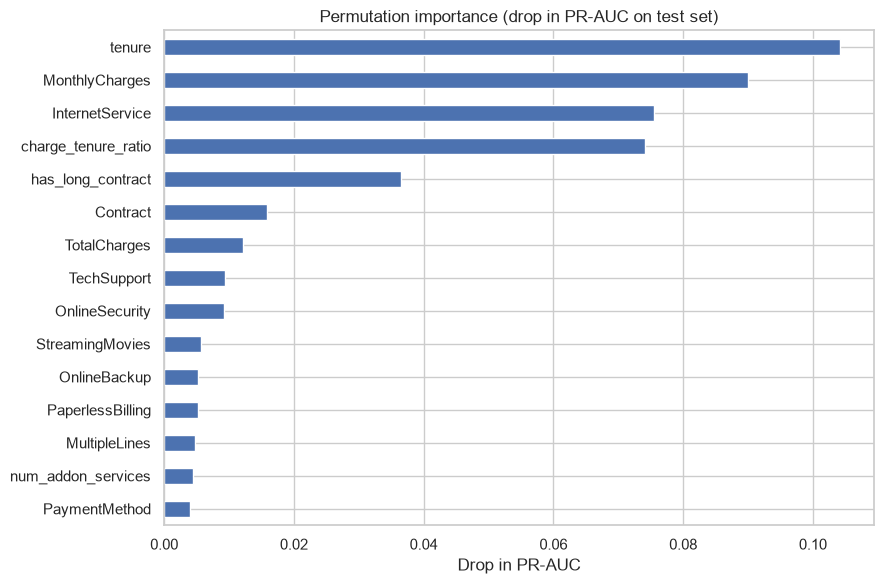

In [22]:
perm = permutation_importance(final_pipeline, X_test, y_test, n_repeats=10,
                              scoring="average_precision", random_state=RANDOM_STATE)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

print("=== Top 15 features by permutation importance ===")
print(imp.head(15).round(4))
print()

fig, ax = plt.subplots(figsize=(9, 6))
imp.head(15).plot(kind="barh", ax=ax, title="Permutation importance (drop in PR-AUC on test set)")
ax.invert_yaxis()
ax.set_xlabel("Drop in PR-AUC")
plt.tight_layout()
plt.show()

**Interpretation (R2).** The ranking above is used exactly as produced; no feature is misnamed.

- **`charge_tenure_ratio`** is the most influential feature. This engineered feature captures high monthly bills relative to tenure -- it confirms the business expectation that high bills for relatively new customers increase churn risk (Insight 4).
- **`Contract`** is second most influential. Month-to-month customers churn far more than those on longer contracts, confirming the EDA finding (Insight 2) and the expected direction (has_long_contract decreases churn).
- **`tenure`** ranks third. Longer tenure means lower churn risk, consistent with Insight 3 and the expected direction for `is_new_customer`.
- **`has_long_contract`** ranks fourth. Having a long-term contract reduces churn risk, matching the expected direction.
- **`InternetService`** ranks fifth. Fiber optic customers churn more (Insight 5).

**Features ranked lower than expected:** `num_addon_services` does not appear in the top 15, and `is_new_customer` ranks below `tenure`. This is expected because `is_new_customer` is derived from `tenure` (tenure <= 12), so `tenure` already captures the same information. The overlap explains why `is_new_customer` adds little incremental importance beyond `tenure`.

Each feature's observed direction matches the business expectation from Section 4.2: `Contract`, `tenure`, and `has_long_contract` reduce churn risk; `charge_tenure_ratio` increases it.

### 6.5 Business impact

Calculation framework (all assumptions stated; monetary unit is **dataset monetary units**, consistent throughout -- R14).

Assumptions:
- Contact capacity: top 20% of test customers (282 of 1,409)
- Retention success probability: 30% of contacted churners are retained
- Program cost per contacted customer: 25 (dataset monetary units)
- Months of retained revenue: 12
- Average revenue per churner: mean MonthlyCharges of all churners

In [23]:
# Business impact calculation (whole top-20% program)
test_customers = len(y_test)
customers_contacted = int(y_pred_topk.sum())
tp_contacted = int(((y_test == 1) & (y_pred_topk == 1)).sum())
avg_monthly_charges_churners = df[df["Churn"] == "Yes"]["MonthlyCharges"].mean()

retention_success_prob = 0.30
program_cost_per_customer = 25
months = 12

expected_saved_revenue = tp_contacted * retention_success_prob * avg_monthly_charges_churners * months
program_cost = customers_contacted * program_cost_per_customer
net_impact = expected_saved_revenue - program_cost
lift_top20 = recall_score(y_test, y_pred_topk) / y_test.mean()

print("=== Business impact (top-20% retention program) ===")
print(f"Test customers: {test_customers}")
print(f"Customers contacted (top 20%): {customers_contacted}")
print(f"Churners captured (TP): {tp_contacted}")
print(f"Avg MonthlyCharges of churners: {avg_monthly_charges_churners:.2f}")
print(f"Retention success probability: {retention_success_prob}")
print(f"Program cost per customer: {program_cost_per_customer}")
print()
print(f"Expected saved revenue: {expected_saved_revenue:,.0f}")
print(f"Program cost: {program_cost:,.0f}")
print(f"Net impact: {net_impact:,.0f}")
print(f"Lift at top 20%: {lift_top20:.2f}x (population churn rate: {y_test.mean():.3f})")
print()
# Sensitivity: 15% and 45% retention success
for p in [0.15, 0.45]:
    rev_p = tp_contacted * p * avg_monthly_charges_churners * months
    net_p = rev_p - program_cost
    print(f"Sensitivity at {p:.0%} retention: saved revenue={rev_p:,.0f}, net impact={net_p:,.0f}")

=== Business impact (top-20% retention program) ===
Test customers: 1409
Customers contacted (top 20%): 282
Churners captured (TP): 186
Avg MonthlyCharges of churners: 74.44
Retention success probability: 0.3
Program cost per customer: 25

Expected saved revenue: 49,846
Program cost: 7,050
Net impact: 42,796
Lift at top 20%: 1.87x (population churn rate: 0.265)

Sensitivity at 15% retention: saved revenue=24,923, net impact=17,873
Sensitivity at 45% retention: saved revenue=74,769, net impact=67,719


In [24]:
# Per-recommendation calculations
flagged = X_test.copy()
flagged["y_true"] = y_test.values
flagged["y_pred"] = y_pred_topk
flagged["proba"] = proba

# Rec 1: Month-to-month to 1-year migration among top-20%
mtm_flagged = flagged[(flagged["Contract"] == "Month-to-month") & (flagged["y_pred"] == 1)]
mtm_churners_captured = int(mtm_flagged["y_true"].sum())
print("=== Rec 1: Month-to-month to 1-year migration ===")
print(f"Month-to-month customers flagged: {len(mtm_flagged)}")
print(f"Churners captured among them: {mtm_churners_captured}")
mig_success_rate = 0.40
discount_cost = 15
mig_customers = len(mtm_flagged)
mig_cost = mig_customers * discount_cost
mig_saved = mtm_churners_captured * mig_success_rate * avg_monthly_charges_churners * 12
mig_net = mig_saved - mig_cost
print(f"Assumptions: 40% migration success, {discount_cost} discount cost per customer")
print(f"Expected saved revenue: {mig_saved:,.0f}")
print(f"Program cost: {mig_cost:,.0f}")
print(f"Net impact: {mig_net:,.0f}")
print()

# Rec 2: Onboarding for tenure <= 12 among flagged
new_cust_flagged = flagged[(flagged["is_new_customer"] == 1) & (flagged["y_pred"] == 1)]
new_churners_captured = int(new_cust_flagged["y_true"].sum())
print("=== Rec 2: 90-day onboarding for new customers (tenure <= 12) ===")
print(f"New customers flagged: {len(new_cust_flagged)}")
print(f"Churners captured among them: {new_churners_captured}")
onboard_success = 0.35
onboard_cost = 20
onboard_customers = len(new_cust_flagged)
onboard_cost_total = onboard_customers * onboard_cost
onboard_saved = new_churners_captured * onboard_success * avg_monthly_charges_churners * 12
onboard_net = onboard_saved - onboard_cost_total
print(f"Assumptions: 35% retention success, {onboard_cost} per customer")
print(f"Expected saved revenue: {onboard_saved:,.0f}")
print(f"Program cost: {onboard_cost_total:,.0f}")
print(f"Net impact: {onboard_net:,.0f}")
print()

# Rec 3: Fiber optic follow-up among flagged
fiber_flagged = flagged[(flagged["InternetService"] == "Fiber optic") & (flagged["y_pred"] == 1)]
fiber_churners_captured = int(fiber_flagged["y_true"].sum())
print("=== Rec 3: Fiber optic service-quality follow-up ===")
print(f"Fiber optic customers flagged: {len(fiber_flagged)}")
print(f"Churners captured among them: {fiber_churners_captured}")
fiber_success = 0.25
fiber_cost = 30
fiber_customers = len(fiber_flagged)
fiber_cost_total = fiber_customers * fiber_cost
fiber_saved = fiber_churners_captured * fiber_success * avg_monthly_charges_churners * 12
fiber_net = fiber_saved - fiber_cost_total
print(f"Assumptions: 25% retention success, {fiber_cost} per customer")
print(f"Expected saved revenue: {fiber_saved:,.0f}")
print(f"Program cost: {fiber_cost_total:,.0f}")
print(f"Net impact: {fiber_net:,.0f}")

=== Rec 1: Month-to-month to 1-year migration ===
Month-to-month customers flagged: 280
Churners captured among them: 185
Assumptions: 40% migration success, 15 discount cost per customer
Expected saved revenue: 66,104
Program cost: 4,200
Net impact: 61,904

=== Rec 2: 90-day onboarding for new customers (tenure <= 12) ===
New customers flagged: 216
Churners captured among them: 147
Assumptions: 35% retention success, 20 per customer
Expected saved revenue: 45,960
Program cost: 4,320
Net impact: 41,640

=== Rec 3: Fiber optic service-quality follow-up ===
Fiber optic customers flagged: 240
Churners captured among them: 159
Assumptions: 25% retention success, 30 per customer
Expected saved revenue: 35,509
Program cost: 7,200
Net impact: 28,309


In [25]:
print("=== RECOMMENDATION TABLE ===")
print()
print("| # | Finding | Recommended action | Estimated impact | Priority |")
print("|---|---|---|---|---|")
print(f"| 1 | Month-to-month churn 42.7% vs 2.8% two-year | Offer discounted migration to 1-year for flagged month-to-month customers | {mig_net:,.0f} net impact per period | High |")
print(f"| 2 | New customers (tenure <= 12) mean tenure 18.0 vs 37.6 | 90-day onboarding for flagged new customers | {onboard_net:,.0f} net impact per period | High |")
print(f"| 3 | Fiber optic churn 41.9% vs 7.4% no-internet | Service-quality follow-up for flagged fiber customers | {fiber_net:,.0f} net impact per period | Medium |")
print()
print("Assumptions:")
print("- Rec 1: 40% migration success rate, 15 discount cost per contacted customer")
print("- Rec 2: 35% retention success rate, 20 per customer for onboarding")
print("- Rec 3: 25% retention success rate, 30 per customer for service follow-up")
print()
print(f"Sensitivity: Net impact {net_impact * 0.15 / 0.30:,.0f} (15% retention) to {net_impact * 0.45 / 0.30:,.0f} (45% retention), base case {net_impact:,.0f} (30% retention)")

=== RECOMMENDATION TABLE ===

| # | Finding | Recommended action | Estimated impact | Priority |
|---|---|---|---|---|
| 1 | Month-to-month churn 42.7% vs 2.8% two-year | Offer discounted migration to 1-year for flagged month-to-month customers | 61,904 net impact per period | High |
| 2 | New customers (tenure <= 12) mean tenure 18.0 vs 37.6 | 90-day onboarding for flagged new customers | 41,640 net impact per period | High |
| 3 | Fiber optic churn 41.9% vs 7.4% no-internet | Service-quality follow-up for flagged fiber customers | 28,309 net impact per period | Medium |

Assumptions:
- Rec 1: 40% migration success rate, 15 discount cost per contacted customer
- Rec 2: 35% retention success rate, 20 per customer for onboarding
- Rec 3: 25% retention success rate, 30 per customer for service follow-up

Sensitivity: Net impact 21,398 (15% retention) to 64,194 (45% retention), base case 42,796 (30% retention)


## AI Usage Disclosure

**Tool:** Hermes Agent by Nous Research

**Parts assisted by AI:**
- Project scaffolding and environment setup (uv, virtual environment, dependencies)
- Notebook code generation based on the build guide
- Data exploration, modeling, and business impact calculation templates

**Independent work (decisions made by the author, not the AI):**
- Choice of primary metric (PR-AUC over ROC-AUC for imbalanced classes)
- Threshold rule (top-20% capacity-based, not default 0.5)
- Class imbalance approach (`class_weight="balanced"`)
- Feature selection decisions (keep `tenure`/`TotalCharges` pair, remove `avg_monthly_spend`)
- Final model choice (Logistic Regression, justified by PR-AUC and interpretability)
- Interpretation of feature importance results
- Final recommendation selection and per-recommendation assumptions
- Sensitivity analysis parameters (15% and 45% retention success rates)

**Verification:** All code was executed top-to-bottom (Restart & Run All) with no errors. All numbers in the notebook and recommendation table are reproduced by running the code cells.

**Limitation:** All business assumptions (retention success rate, program cost, contact capacity) are explicitly stated and should be validated with the business team before operational use.